<a href="https://colab.research.google.com/github/yy1010yy/data-science-toolkit/blob/main/Tutorial3_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 1. Find some real dataset. Load it on Colab, Kaggle etc. Try to visualize some of it

In [3]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/2026-27-S1-Intro to data science/datasets/titanic/train.csv")
display(df.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# 2. Is the dataset good? Does it have enough data?

In [4]:
print("Rows and columns", df.shape)
print("Repeated PassengerId values: ", df["PassengerId"].duplicated().sum())
print("Survived values (0 - No, 1 - Yes): ")
print(df["Survived"].value_counts())

Rows and columns (891, 12)
Repeated PassengerId values:  0
Survived values (0 - No, 1 - Yes): 
Survived
0    549
1    342
Name: count, dtype: int64


# 3. How many features does it have? Is it enough?

Features are info that might help answer a question.

In [7]:
print("All columns: ")
print(df.columns.tolist())
print("Number of columns: ", len(df.columns))
print("Possible input columns (excluding Survived): ", len(df.columns) - 1)

All columns: 
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Number of columns:  12
Possible input columns (excluding Survived):  11


Answer: There are 112 columns: one outcome (Survived) and 11 other columns.

# 4. How many samples/observation does it have? Is it enough?

In [ ]:
print("Number of passengers: ", len(df))

Answer: 891 observations in the standard Kaggle train.csv. That is enough to calculate summaries and create beginner charts, but whether it is sufficient for a reliable prediction model depends.

# 5. What are the datatypes does the dataset consist of?

In [8]:
print(df.dtypes)

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


int64 refers to whole numbers, float64 means decimal numbers and object usually means text

# 6 and 8. How many columns have null values? If yes, which column, which rows

In [10]:
missing =  df.isnull().sum()
print("Missing values in each column: ")
print(missing)
print("\nColumns with any missing values: ")
print(missing[missing > 0])
print("\nNumber of columns with missing values:", (missing > 0).sum())

Missing values in each column: 
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Columns with any missing values: 
Age         177
Cabin       687
Embarked      2
dtype: int64

Number of columns with missing values: 3


# 7. Which column is the feature, which is the target output?

In [11]:
target = "Survived"
features = df.drop(columns=["Survived", "PassengerId"])

print("Target: ", target)
print("Features: ", features.columns.tolist())
print("Target values: ", df[target].unique())

Target:  Survived
Features:  ['Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Target values:  [0 1]


Answer: Target is Survived (0 = did not survie; 1 = survived). The featyres are passenger details used to investigate survival. PassengerId is excluded form features because it identifies a passenger rather than describing their circumstances. No prediction model is trained in this exercise.

Percentage who survived in each class: 
Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64


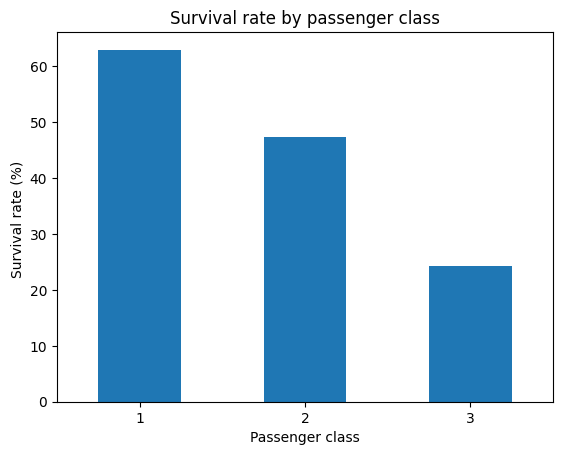

In [13]:
survival_rate = df.groupby("Pclass")["Survived"].mean() * 100
print("Percentage who survived in each class: ")
print(survival_rate.round(1))

survival_rate.plot(kind="bar")
plt.title("Survival rate by passenger class")
plt.xlabel("Passenger class")
plt.ylabel("Survival rate (%) ")
plt.xticks(rotation=0)
plt.show()